# 笔记 2：Data and Setting 的写作底稿

这份笔记把论文 **Section 3（Data and Setting）** 需要的数据、定义和结果集中在一处，供你梳理思路、自己写作。

- **数据：** Hugging Face Hub 快照 `modelbiome/ai_ecosystem_withmodelcards`，最新模型创建于 2025-07-12。
- **口径：** v2 主规格，即 (d+1) PPS 候选集、方案 A（每个作者–父模型对的首次采纳）、24 小时会话。和论文、`results/tables/v2/` 完全一致。
- **代码：** 单元格已经运行过，输出就是结果。要重跑，在计算节点上执行 `jupyter nbconvert --execute`，大约需要 64 GB 内存。
- **最后一节**把论文里引用的数字宏（`tables/numbers.tex`）和这里重算的值逐一核对。

**目录**
0. 写作思路：这一节要讲清什么、按什么顺序讲
1. 原始数据：来源与字段
2. 节点表：字段解释与描述统计
3. 边表：字段、清洗漏斗、边的类型
4. 从边到"选择"：哪些边算一次基座模型选择
5. 从上传到决策：会话合并与首次采纳
6. 市场：开发者面对多少备选
7. 集中度：动机性事实
8. 被选中的父模型是什么样的
9. 开发者能看到的信号：四组特征
10. 防照抄：继承检验与卡片文本清洗
11. 训练集与留出集
12. 数字核对：论文宏与本笔记重算值
13. 写作时要处理的问题与待办

## 0. 写作思路

### 0.1 这一节的任务
Section 3 要让读者在进入模型（Section 4）之前接受三件事：
1. **"选择"是一个定义良好、可以测量的对象。** 一个开发者在某个时刻，从当时已存在的模型里选一个作为基座。
2. **这个市场极度集中，而且集中有几种相互竞争的解释。** 流行、通用质量、需求匹配都能产生集中，这就是全文要回答的问题。
3. **我们测量的信号是开发者当时能看到的，并且不会机械地偏向真实父模型。** 不能用到未来信息；不能用子模型从父模型照抄来的元数据。

### 0.2 建议的段落顺序（和现在的草稿一致）

| # | 段落 | 一句话主张 | 关键数字 | 本笔记 |
|---|---|---|---|---|
| 1 | 数据与网络 | 模型卡中声明的 base model 定义了一个有向网络；微调和适配器是"选择"，量化和合并不是 | 1,860,413 个模型；574,531 条边；4 种类型的数量 | §1–§4 |
| 2 | 时间窗口 | 2022-03-02 之前的时间戳是回填的，只作初始网络；此后每条选择边都是一次选择 | 选择窗口起止；422,714 次选择 | §2、§4 |
| 3 | 从上传到决策 | 同一作者对同一父模型的连续上传是一次决策；主样本是首次采纳 | 199,464 个决策；133,390 次首次采纳；69,763 位作者；15,450 个父模型 | §5 |
| 4 | 市场 | 市场 = 同模态、更早创建、作者没用过的全部模型；规模极大 | 中位数 344,678 个备选；75% 是文本 | §6 |
| 5 | 集中度 | 极度集中，但集中本身不能区分三种解释 | Top-1 6.8%，Top-10 21.9%，有效父模型数 839 | §7、§8 |
| 6 | 四组信号 | 流行 / 通用质量 / 需求匹配 / 惯性，都只用选择之前的信息 | 26 个特征；需求信号覆盖率 | §9 |
| 7 | 防照抄 | 子模型元数据大量继承自父模型，所以需求只从不被照抄的来源读取 | κ：参数量 0.84，许可证 0.74，数据集 0.12 | §10 |
| 8 | 训练与留出 | 按时间留出最后 10%；固定效应集合在留出切点事前确定 | 117,509 次训练选择；留出切点 2025-05-05 | §11 |

### 0.3 主文放什么、附录放什么
- **主文：** 每段一到两个最关键的数字；一张描述性的图，推荐 §7 的集中度图（CCDF 或 Lorenz 曲线），也可以用"被选父模型的 degree 分布"。
- **附录 A：** 清洗漏斗（§3）、特征定义表（§9）、继承检验表（§10）、卡片文本清洗统计（§10）、按模态的分解（§6、§7）。
- **可以考虑新增一张"样本构造"表：** 从原始模型一路到训练集的每一步样本量（§4、§5、§11 已经算好）。EC 的审稿人通常想看这张表。

### 0.4 EC 读者在这一节最可能追问的问题
（§13 有更完整的清单。）
- **声明的 base model 是否可靠？** 它是自报的，有遗漏、错报和删库。
- **为什么只看首次采纳？** 批量账号和重复上传的问题。
- **市场为什么按模态划分？** 开发者真的会考虑几十万个模型吗？这和 Section 4 的抽样设计如何衔接？
- **集中度来自少数作者的大量上传，还是很多作者独立的选择？**

In [1]:
import os, sys, re, json
os.environ.setdefault("ACMEC_DATA_ROOT", "/net/spaces/jevans/klab/caroyf/data/ACMEC")
sys.path.insert(0, "/home/caroyf/myproject/ACMEC/src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from IPython.display import display, Markdown
from hfpa import paths
from hfpa.features.groups import GROUPS, ALL, SIGNAL, redistributors

pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200)
T = paths.TABLES / "v2"
SPEC = paths.PROCESSED / "choices" / "v2_pps"
REPO = paths.REPO
# chart palette (categorical slots 1-4 of the reference palette; gray for "other")
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; GRAY = "#8a8984"; INK2 = "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "lines.linewidth": 2,
                     "font.size": 10, "legend.frameon": False})
ts = lambda s: pd.to_datetime(s, unit="s")
pct = lambda x, d=1: f"{100 * x:.{d}f}%"
def yearly(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
def show(df, n=None):
    display(df if n is None else df.head(n))
def eff_n(counts):
    p = np.asarray(counts, float); p = p[p > 0] / p.sum()
    return float(np.exp(-(p * np.log(p)).sum()))
def gini(counts):
    x = np.sort(np.asarray(counts, float)); x = x[x > 0]; n = len(x); i = np.arange(1, n + 1)
    return float(((2 * i - n - 1) * x).sum() / (n * x.sum()))

## 1. 原始数据：来源与字段

| 项目 | 内容 |
|---|---|
| 来源 | Hugging Face 数据集 `modelbiome/ai_ecosystem_withmodelcards`，文件 `ai_ecosystem_withmodelcards.csv`（5.2 GB） |
| 内容 | Hub 上全部公开模型的元数据和完整模型卡文本 |
| 规模 | 1,860,411 个模型 × 23 列；`model_id` 唯一；全部 `private = False` |
| 快照时间 | 最大 `createdAt` 为 2025-07-12 17:14:09 UTC |
| 回填 | `createdAt` ≤ 2022-03-02 23:29:05 的 29,794 个模型（集中在两个时间戳上）是回填的，真实创建时间未知 |
| 抓取问题 | 619,197 行的 `exception_raised` 非空：模型卡抓取出错，但元数据仍在 |

**写作提示：** 论文里要引用数据集来源并写明快照日期，这是 Section 3 的 todo。原始审计见 `results/tables/data_audit.md`。

In [2]:
raw = pd.read_csv(paths.RAW / "ai_ecosystem_withmodelcards.csv", nrows=3, dtype=str)
ex = raw.T.rename(columns=lambda i: f"例 {i + 1}")
ex = ex.apply(lambda s: s.str.slice(0, 90))
print("原始列：", list(raw.columns))
show(ex)

原始列： ['Unnamed: 0', 'model_id', 'likes', 'trendingScore', 'private', 'downloads', 'tags', 'pipeline_tag', 'library_name', 'createdAt', 'regions', 'licenses', 'arxiv_papers', 'datasets', 'parent_model', 'finetune_parent', 'quantized_parent', 'adapter_parent', 'merge_parent', 'languages', 'modelCard', 'ratelimit_retries', 'exception_raised']


,例 1,例 2,例 3
Unnamed: 0,0,1,2
model_id,moonshotai/Kimi-K2-Instruct,THUDM/GLM-4.1V-9B-Thinking,HuggingFaceTB/SmolLM3-3B
likes,479,569,351
trendingScore,479.0,367.0,351.0
private,False,False,False
downloads,13356,33839,21863
tags,"['transformers', 'safetensors', 'kimi_k2', 'text-generation', 'conversational', 'custom_co","['transformers', 'safetensors', 'glm4v', 'image-text-to-text', 'reasoning', 'conversationa","['transformers', 'safetensors', 'smollm3', 'text-generation', 'conversational', 'en', 'fr'"
pipeline_tag,text-generation,image-text-to-text,text-generation
library_name,transformers,transformers,transformers
createdAt,2025-07-11T00:55:12.000Z,2025-06-28T14:24:10.000Z,2025-07-08T10:11:45.000Z


**原始字段的含义和用途**（加粗的是构建网络必需的字段）

| 字段 | 含义 | 本项目中的用途 |
|---|---|---|
| `model_id` | 仓库 id，格式为`作者/模型名` | 节点主键；作者取 `/` 前面的部分（数据里没有单独的作者列） |
| **`createdAt`** | 创建时间（UTC） | 选择发生的时刻；所有"之前"的判断都以它为准 |
| **`tags`** | Hub 标签，包括 `base_model:<id>` 和带类型的 `base_model:<rel>:<id>` | **边的来源**：解析器保留带类型的那一个标签 |
| `parent_model`、`finetune_parent`、`adapter_parent`、`quantized_parent`、`merge_parent` | 数据集自带的父模型列，按类型分开 | 与 tags 解析结果核对；tags 另外多出 832 条无类型的父模型 |
| `pipeline_tag` | 任务标签，如 `text-generation` | 模态划分；需求匹配中的任务 |
| `library_name` | 框架，如 transformers、peft、diffusers | 库生态特征；模态的后备来源 |
| `languages` | 声明的语言 | 需求匹配中的语言 |
| `datasets` | 声明的训练数据集 | 数据集需求档案 |
| `licenses` | 许可证 | 许可证类别（大多照抄父模型，不作需求） |
| `likes`、`downloads`、`trendingScore` | 快照时的点赞数、近 30 天下载量、热度分 | 只作描述；这些是快照时点的值，不是选择当时的值，所以不进模型 |
| `arxiv_papers` | 关联论文 | 节点属性 `has_arxiv` |
| **`modelCard`** | 模型卡原文（YAML 头加 markdown） | model-index 中的 benchmark 分数（通用质量）；卡片文本相似度（需求匹配） |
| `regions`、`private`、`ratelimit_retries`、`exception_raised` | 抓取元信息 | 未使用 |

**一个要在正文说明的点：** `likes` 和 `downloads` 都是快照时的值，会泄露未来信息。模型里的流行信号全部用选择之前的网络状态重新计算：degree、近 30 天的采纳等。

## 2. 节点表：字段解释与描述统计
`processed/nodes/nodes.parquet` 每行一个模型，包括 2 个占位节点（已删除、但子模型 ≥ 100 的父模型）。

In [3]:
nodes = pd.read_parquet(paths.PROCESSED / "nodes" / "nodes.parquet")
NODE_DESC = {
    "model_id": "仓库 id（作者/模型名）",
    "author": "账号名，取 model_id 中 / 前面的部分",
    "createdAt": "原始创建时间（UTC）",
    "pipeline_tag": "任务标签（原始）",
    "library_name": "框架（原始）",
    "downloads": "快照时近 30 天下载量（只作描述）",
    "likes": "快照时的点赞数（只作描述）",
    "trendingScore": "快照时的 Hub 热度分（只作描述）",
    "placeholder": "占位节点：快照中已删除、但被 ≥100 个子模型声明为父模型",
    "legacy": "回填模型：createdAt ≤ 2022-03-02 23:29:05，构成初始网络",
    "birth_ts": "分析用的出生时刻（时间戳）",
    "birth": "分析用的出生时刻（Unix 秒），所有'之前'的判断都按它比较",
    "primary_parent": "主父模型（多个父模型时按 finetune > adapter > unspecified > merge > quantized 取第一个），无则为 -1",
    "root": "家族根：沿主父模型一直向上追溯到的祖先，用于'同家族'特征",
    "generation": "离家族根的代数（根为 0）",
    "is_root": "是否为家族根（没有主父模型）",
    "modality_src": "模态的来源：自己的 pipeline_tag / 父模型 / 库 / 无法判断",
    "modality": "粗模态：text、image_gen、vision、speech、multimodal、other、unknown",
    "modality_code": "modality 的整数编码",
    "major_org": "由大型 AI 机构发布（手工名单，不含 unsloth、TheBloke 等再分发账号）",
    "license_cat": "许可证类别（apache、mit、llama、gemma、openrail、非商用……）",
    "library_cat": "框架类别",
    "params_b": "参数量（十亿），从模型名解析（如 7b、350m），解析不到为缺失",
    "has_arxiv": "是否关联 arXiv 论文",
    "author_code": "作者的整数编码",
}
def profile(df, desc):
    rows = []
    for c in df.columns:
        s = df[c]
        ex = s.dropna().iloc[len(s.dropna()) // 2] if s.notna().any() else None
        rows.append(dict(字段=c, 类型=str(s.dtype), 非空=pct(s.notna().mean()), 不同值=f"{s.nunique():,}",
                         示例=str(ex)[:60], 含义=desc.get(c, "")))
    return pd.DataFrame(rows).set_index("字段")
show(profile(nodes, NODE_DESC))

,类型,非空,不同值,示例,含义
字段,,,,,
model_id,str,100.0%,"1,860,413",yenslife/it-ironman-llama3-demo,仓库 id（作者/模型名）
author,str,100.0%,"391,746",yenslife,账号名，取 model_id 中 / 前面的部分
createdAt,"datetime64[us, UTC]",100.0%,"1,784,447",2024-09-18 18:43:30+00:00,原始创建时间（UTC）
pipeline_tag,str,38.4%,54,text-generation,任务标签（原始）
library_name,str,56.1%,630,diffusers,框架（原始）
downloads,float64,100.0%,"9,671",6.0,快照时近 30 天下载量（只作描述）
likes,float64,100.0%,815,0.0,快照时的点赞数（只作描述）
trendingScore,float64,100.0%,81,0.0,快照时的 Hub 热度分（只作描述）
placeholder,bool,100.0%,2,False,占位节点：快照中已删除、但被 ≥100 个子模型声明为父模型


In [4]:
N = len(nodes)
print(f"节点 {N:,}；作者（账号）{nodes.author_code.nunique():,}；占位节点 {int(nodes.placeholder.sum())}；"
      f"回填（legacy）{int(nodes.legacy.sum()):,}（{pct(nodes.legacy.mean())}）")
by_mod = nodes.groupby("modality").agg(模型数=("model_id", "size"), 回填=("legacy", "sum"),
                                         大机构=("major_org", "mean"), 有参数量=("params_b", lambda s: s.notna().mean()))
by_mod["占比"] = by_mod.模型数 / N
by_mod = by_mod.sort_values("模型数", ascending=False)
show(by_mod.style.format({"模型数": "{:,}", "回填": "{:,}", "大机构": "{:.2%}", "有参数量": "{:.1%}", "占比": "{:.1%}"}))
print("模态来源：")
show(nodes.modality_src.value_counts(normalize=True).rename("占比").to_frame().style.format("{:.1%}"))

节点 1,860,413；作者（账号）391,746；占位节点 2；回填（legacy）29,794（1.6%）


,模型数,回填,大机构,有参数量,占比
modality,,,,,
unknown,"840,948","8,928",0.24%,18.0%,45.2%
text,"764,428","18,647",0.44%,44.4%,41.1%
image_gen,"94,373",15,0.27%,0.9%,5.1%
other,"63,638",23,0.05%,1.1%,3.4%
speech,"40,873","1,787",3.67%,6.7%,2.2%
vision,"28,973",362,2.32%,1.1%,1.6%
multimodal,"27,180",32,2.24%,32.2%,1.5%


模态来源：


,占比
modality_src,
lib/unknown,45.1%
own,38.4%
parent,16.5%


In [5]:
print("框架类别（前 10）："); show(nodes.library_cat.value_counts(normalize=True).head(10).rename("占比").to_frame().style.format("{:.1%}"))
print("许可证类别："); show(nodes.license_cat.value_counts(normalize=True).rename("占比").to_frame().style.format("{:.1%}"))
q = nodes.params_b.quantile([.1, .25, .5, .75, .9, .99])
print(f"参数量（十亿，从名称解析；覆盖 {pct(nodes.params_b.notna().mean())}）分位数："); show(q.rename("params_b").to_frame().T)
per_a = nodes.groupby("author_code").size()
print("每个账号的模型数：", per_a.describe(percentiles=[.5, .9, .99]).round(1).to_dict())
top_a = nodes.author.value_counts().head(10)
print(f"模型最多的 10 个账号合计 {pct(top_a.sum() / N)}："); show(top_a.rename("模型数").to_frame())

框架类别（前 10）：


,占比
library_cat,
none,43.9%
transformers,35.4%
peft,11.2%
diffusers,4.7%
other,3.6%
sentence-transformers,0.7%
keras,0.1%
mlx,0.1%
timm,0.1%


许可证类别：


,占比
license_cat,
none,63.9%
apache,16.0%
mit,5.9%
other,5.6%
openrail,4.1%
llama,1.9%
noncommercial,1.1%
cc_by,0.6%
gemma,0.5%


参数量（十亿，从名称解析；覆盖 27.1%）分位数：


,0.10,0.25,0.50,0.75,0.90,0.99
params_b,0.5,1.8,7.0,8.0,27.0,846.0


每个账号的模型数： {'count': 391746.0, 'mean': 4.7, 'std': 98.5, 'min': 1.0, '50%': 1.0, '90%': 6.0, '99%': 41.0, 'max': 42722.0}


模型最多的 10 个账号合计 7.0%：


,模型数
author,
mradermacher,42722
RichardErkhov,25704
Krabat,12206
xueyj,11984
PrunaAI,10377
SALUTEASD,7022
John6666,5597
downtown1,5160
manbull,5108


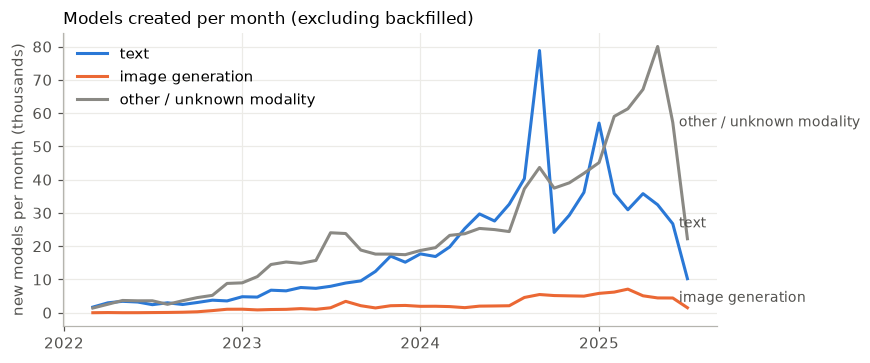

In [6]:
# monthly births by modality (non-legacy)
b = nodes[~nodes.legacy].copy()
b["month"] = ts(b.birth).dt.to_period("M").dt.to_timestamp()
b["grp"] = np.where(b.modality.isin(["text", "image_gen"]), b.modality, "其他模态")
m = b.groupby(["month", "grp"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.4))
for col, color, lab in [("text", C[0], "text"), ("image_gen", C[1], "image generation"), ("其他模态", GRAY, "other / unknown modality")]:
    ax.plot(m.index, m[col] / 1e3, color=color, label=lab)
    ax.annotate(lab, (m.index[-2], m[col].iloc[-2] / 1e3), xytext=(4, 0), textcoords="offset points",
                color=INK2, fontsize=9, va="center")
ax.set_ylabel("new models per month (thousands)"); ax.set_title("Models created per month (excluding backfilled)", loc="left", fontsize=11)
ax.legend(loc="upper left"); yearly(ax); plt.tight_layout(); plt.show()

**写作要点：**
- 节点里有 45% 的模态是 unknown：没有 pipeline_tag、没有父模型，库也无法判断模态。在首次采纳中只占 1.2%。
- 正文只需要说明模态如何确定：自己的任务标签 → 父模型 → 库。
- 每个账号的模型数极度偏斜：中位数 1，最多 42,722（mradermacher，主要是量化副本）。

## 3. 边表：字段、清洗漏斗、边的类型
`processed/edges/edges.parquet` 每行一条"父模型 → 子模型"的声明。

In [7]:
E = pd.read_parquet(paths.PROCESSED / "edges" / "edges.parquet")
EDGE_DESC = {
    "child": "子模型 id",
    "parent": "父模型 id（模型卡声明的 base model）",
    "rel_type": "关系类型：finetune 全参数微调；adapter 适配器（LoRA 等）；quantized 量化版本；merge 合并；unspecified 未注明类型",
    "match": "父模型 id 如何匹配到节点：exact 精确；lowercase 忽略大小写；placeholder 匹配到占位节点",
    "weight": "merge 边为 1/m（m 为该子模型的合并父模型数），其余为 1",
    "child_idx": "子模型在节点表中的行号",
    "parent_idx": "父模型在节点表中的行号",
}
show(profile(E, EDGE_DESC))
print("清洗漏斗（P2）：")
show(pd.read_csv(paths.TABLES / "cleaning_funnel.csv"))

,类型,非空,不同值,示例,含义
字段,,,,,
child,str,100.0%,"546,905",fbaldassarri/HuggingFaceTB_SmolLM2-360M-Instruct-auto_gptq-i,子模型 id
parent,str,100.0%,"49,928",HuggingFaceTB/SmolLM2-360M-Instruct,父模型 id（模型卡声明的 base model）
rel_type,str,100.0%,5,quantized,关系类型：finetune 全参数微调；adapter 适配器（LoRA 等）；quantized 量化版本；merge 合并；unspecified 未注明类型
match,str,100.0%,3,exact,父模型 id 如何匹配到节点：exact 精确；lowercase 忽略大小写；placeholder 匹配到占位节点
weight,float64,100.0%,31,1.0,merge 边为 1/m（m 为该子模型的合并父模型数），其余为 1
child_idx,int64,100.0%,"546,905",1291293,子模型在节点表中的行号
parent_idx,int64,100.0%,"49,928",1047054,父模型在节点表中的行号


清洗漏斗（P2）：


,step,kept,removed
0,parsed base_model tags,582598,0
1,"dedupe (child, parent) pairs",582001,597
2,parent matched exactly,573840,0
3,parent matched case-insensitively,25,0
4,drop self loops,580736,1265
5,dangling parents kept as placeholders (>= 100 children),3582,0
6,drop dangling parents (not in snapshot),576182,4554
7,drop child created before parent,574531,1651
8,drop equal timestamps (non-legacy),574531,0
9,drop edges on cycles,574531,0


**清洗规则**（附录 A 第一段）：
- 同一个（子，父）有多种类型时，按优先级只保留一条；
- 去掉自环；
- 去掉父模型不在快照中的边，但子模型 ≥ 100 的已删除父模型补为占位节点（例如 `runwayml/stable-diffusion-v1-5` 有 3,192 条边）；
- 去掉子模型早于父模型的边；
- 去掉非回填模型之间时间戳相同的边。

去掉的边一共约 1.4%。

In [8]:
rt = E.rel_type.value_counts().rename("边数").to_frame()
rt["占比"] = rt.边数 / len(E)
rt["是否算作选择"] = rt.index.map({"finetune": "是", "adapter": "是", "unspecified": "是（按微调处理）",
                                 "quantized": "否：作为父模型的属性（量化版本数）", "merge": "否：多父合并，不是选一个基座"})
show(rt.style.format({"边数": "{:,}", "占比": "{:.1%}"}))
k = E.groupby("child").size()
print(f"有父模型的子模型 {len(k):,} 个；每个子模型的父模型数：1 个占 {pct((k == 1).mean())}，"
      f"≥2 个占 {pct((k >= 2).mean())}，最多 {k.max()}")
kc = E[E.rel_type.isin(["finetune", "adapter", "unspecified"])].groupby("child").size()
print(f"只看选择类边：{len(kc):,} 个子模型，1 个父模型的占 {pct((kc == 1).mean())}")
print("边的匹配方式："); show(E.match.value_counts().rename("边数").to_frame())

,边数,占比,是否算作选择
rel_type,,,
adapter,"243,643",42.4%,是
finetune,"188,819",32.9%,是
quantized,"101,095",17.6%,否：作为父模型的属性（量化版本数）
merge,"40,220",7.0%,否：多父合并，不是选一个基座
unspecified,754,0.1%,是（按微调处理）


有父模型的子模型 546,905 个；每个子模型的父模型数：1 个占 97.6%，≥2 个占 2.4%，最多 63
只看选择类边：433,029 个子模型，1 个父模型的占 100.0%
边的匹配方式：


,边数
match,
exact,570924
placeholder,3582
lowercase,25


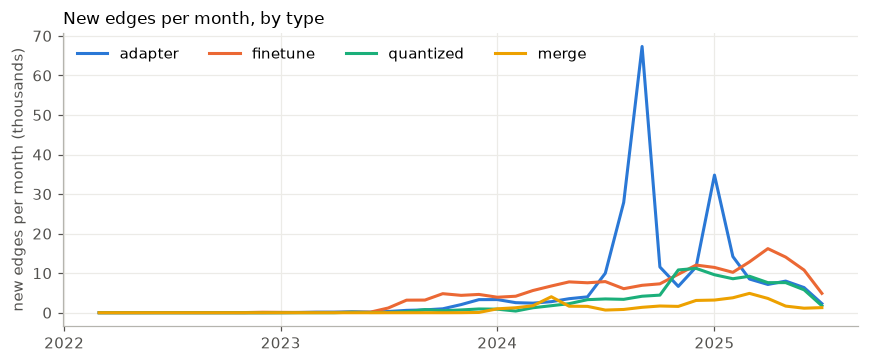

In [9]:
birth = nodes.birth.to_numpy()
e = E.assign(month=ts(birth[E.child_idx]).to_period("M").to_timestamp())
e = e[~nodes.legacy.to_numpy()[E.child_idx]]
m = e.groupby(["month", "rel_type"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(8, 3.4))
for col, color, lab in [("adapter", C[0], "adapter"), ("finetune", C[1], "finetune"), ("quantized", C[2], "quantized"),
                        ("merge", C[3], "merge")]:
    ax.plot(m.index, m[col] / 1e3, color=color, label=lab)
ax.set_ylabel("new edges per month (thousands)"); ax.set_title("New edges per month, by type", loc="left", fontsize=11)
ax.legend(loc="upper left", ncol=4); yearly(ax); plt.tight_layout(); plt.show()

## 4. 从边到"选择"
**定义：** 一次选择是一条类型为 finetune、adapter 或 unspecified 的边，并且满足：
- 子模型在 2022-03-02 回填时刻之后创建；
- 父模型与子模型属于同一模态。

如果一个子模型声明了多个父模型，每个父模型各算一次选择。`choices.parquet` 是重放的结果；`decisions.parquet` 在它的基础上加了会话和首次采纳等标记。

In [10]:
ch = pd.read_parquet(SPEC / "decisions.parquet")
checks = json.loads((SPEC / "checks.json").read_text())
DEC_DESC = {
    "choice_id": "选择编号（按时间排序）",
    "child": "子模型的节点行号",
    "parent": "被选父模型的节点行号",
    "t": "选择时刻 = 子模型出生时刻（Unix 秒）",
    "modality": "模态编码",
    "modality_name": "模态",
    "rel_type": "边的类型",
    "weight": "边权（选择类边均为 1）",
    "n_cands": "PPS 候选集大小（重放时；方案 A 估计时会再删去作者用过的父模型）",
    "parent_deg": "被选父模型在选择前的 degree（此前的 finetune/adapter 子模型数）",
    "holdout": "是否属于留出集（时间最后 10%）",
    "author": "作者编码",
    "sess6": "6 小时窗口下的决策（会话）编号", "dfirst6": "是否为其 6 小时决策的第一次上传",
    "sess24": "24 小时窗口下的决策编号（主规格）", "dfirst24": "是否为其 24 小时决策的第一次上传",
    "sess72": "72 小时窗口下的决策编号", "dfirst72": "是否为其 72 小时决策的第一次上传",
    "pair_first": "是否为该作者–父模型对的首次采纳（方案 A 主样本）",
    "last_parent": "作者此前最近一次用的父模型（任意模态），用于惯性特征 is_last",
    "featurise": "是否计算了候选特征（v2_pps 下等于 dfirst24）",
}
show(profile(ch, DEC_DESC))

,类型,非空,不同值,示例,含义
字段,,,,,
choice_id,int64,100.0%,"422,714",211357,选择编号（按时间排序）
child,int64,100.0%,"422,527",986118,子模型的节点行号
parent,int64,100.0%,"15,450",476374,被选父模型的节点行号
t,int64,100.0%,"417,575",1727847078,选择时刻 = 子模型出生时刻（Unix 秒）
modality,int64,100.0%,7,0,模态编码
rel_type,str,100.0%,3,adapter,边的类型
weight,float64,100.0%,1,1.0,边权（选择类边均为 1）
n_cands,int64,100.0%,725,330,PPS 候选集大小（重放时；方案 A 估计时会再删去作者用过的父模型）
parent_deg,int64,100.0%,"32,984",21791,被选父模型在选择前的 degree（此前的 finetune/adapter 子模型数）


In [11]:
T0 = pd.Timestamp("2022-03-02 23:29:05").timestamp()
is_choice_type = E.rel_type.isin(["finetune", "adapter", "unspecified"]).to_numpy()
after = birth[E.child_idx] > T0
funnel = pd.DataFrame([
    ("全部边", len(E)),
    ("类型为 finetune / adapter / unspecified", int(is_choice_type.sum())),
    ("且子模型在回填时刻之后创建", int((is_choice_type & after).sum())),
    ("且父子同模态（去掉跨模态 %s 条）" % f"{checks['n_modality_mismatch_dropped']:,}",
     int((is_choice_type & after).sum()) - checks["n_modality_mismatch_dropped"]),
    ("= 选择（choices.parquet）", len(ch)),
], columns=["步骤", "数量"])
show(funnel.style.format({"数量": "{:,}"}))
print(f"选择窗口：{ts(ch.t.min()):%Y-%m-%d} 到 {ts(ch.t.max()):%Y-%m-%d}")
tab = pd.crosstab(ch.modality_name, ch.rel_type, margins=True, margins_name="合计")
show(tab.sort_values("合计", ascending=False))

,步骤,数量
0,全部边,"574,531"
1,类型为 finetune / adapter / unspecified,"433,216"
2,且子模型在回填时刻之后创建,"433,058"
3,"且父子同模态（去掉跨模态 10,344 条）","422,714"
4,= 选择（choices.parquet）,"422,714"


选择窗口：2022-03-03 到 2025-07-12


rel_type,adapter,finetune,unspecified,合计
modality_name,,,,
合计,243142,178818,754,422714
text,189636,142104,753,332493
image_gen,47250,8100,1,55351
speech,1932,10850,0,12782
vision,214,10397,0,10611
multimodal,2184,6024,0,8208
unknown,1911,1186,0,3097
other,15,157,0,172


## 5. 从上传到决策：会话合并与首次采纳
**为什么要合并？** 同一个作者常在几小时内对同一个基座反复上传：检查点、超参数扫描、批量生成的 LoRA。这些上传是同一个决策的多个副本，不是多次独立选择。

**规则：** 同一作者、同一父模型、相邻两次上传间隔 ≤ 24 小时，合并为一个决策；6 小时和 72 小时作为敏感性检验。每个作者–父模型对的第一个决策叫**首次采纳**，是主样本。

In [12]:
show(pd.read_csv(T / "v2_sessions.csv"))
pa = ch[ch.pair_first].copy()
per_dec = ch.groupby("sess24").size()
print(f"24 小时窗口：{len(ch):,} 次选择 → {int(ch.dfirst24.sum()):,} 个决策（平均每个决策 {per_dec.mean():.2f} 次上传，"
      f"中位数 {per_dec.median():.0f}，99 分位 {per_dec.quantile(.99):.0f}，最多 {per_dec.max():,}）")
print(f"首次采纳 {len(pa):,} 次，来自 {pa.author.nunique():,} 位作者、{pa.parent.nunique():,} 个父模型；"
      f"重复决策 {int(ch.dfirst24.sum()) - len(pa):,} 个")

,window_h,choices,decisions,pairs,repeat_decisions,uploads_per_decision,p99_uploads,max_uploads
0,6,422714,226542,133390,93152,1.865941,11.0,2400
1,24,422714,199464,133390,66074,2.119250,11.0,2406
2,72,422714,176526,133390,43136,2.394627,14.0,3160


24 小时窗口：422,714 次选择 → 199,464 个决策（平均每个决策 2.12 次上传，中位数 1，99 分位 11，最多 2,406）
首次采纳 133,390 次，来自 69,763 位作者、15,450 个父模型；重复决策 66,074 个


In [13]:
# how concentrated are uploads across authors, before and after reducing to first adoptions?
def author_conc(df, label):
    c = df.groupby("author").size().sort_values(ascending=False)
    n1 = max(1, int(round(0.01 * len(c))))
    return dict(样本=label, 作者数=f"{len(c):,}", 次数=f"{c.sum():,}",
                最多的作者占比=pct(c.iloc[0] / c.sum()), 前10位作者占比=pct(c.iloc[:10].sum() / c.sum()),
                前1pct作者占比=pct(c.iloc[:n1].sum() / c.sum()), 每位作者中位数=f"{c.median():.0f}")
show(pd.DataFrame([author_conc(ch, "全部选择（上传）"), author_conc(ch[ch.dfirst24], "24h 决策"),
                   author_conc(pa, "首次采纳")]).set_index("样本"))
c = pa.groupby("author").size()
print("每位作者的首次采纳次数分布：", c.value_counts().sort_index().head(10).to_dict(), "…；",
      f"只有 1 次的作者占 {pct((c == 1).mean())}，≥10 次的占 {pct((c >= 10).mean())}")

,作者数,次数,最多的作者占比,前10位作者占比,前1pct作者占比,每位作者中位数
样本,,,,,,
全部选择（上传）,"69,763","422,714",2.9%,14.4%,56.7%,1
24h 决策,"69,763","199,464",0.6%,3.9%,32.5%,1
首次采纳,"69,763","133,390",0.5%,2.0%,23.4%,1


每位作者的首次采纳次数分布： {1: 52365, 2: 9370, 3: 3424, 4: 1649, 5: 939, 6: 510, 7: 324, 8: 229, 9: 150, 10: 121} …； 只有 1 次的作者占 75.1%，≥10 次的占 1.2%


**写作要点：** 上表说明，"首次采纳"大幅削弱了批量账号的权重。一个账号对同一个基座上传上千个 LoRA，在首次采纳里只算一次。正文可以用一句话交代这一点，再用一个数字（前 1% 作者占比的前后对比）支撑。

## 6. 市场：开发者面对多少备选
**定义：** 首次采纳 k 的市场 = 与子模型同模态、在子模型之前创建的全部模型，减去作者此前用过的父模型。下面按"同模态、更早创建"计数（作者用过的父模型数量很少，可以忽略）。

In [14]:
mb = {mm: np.sort(birth[nodes.modality_code.to_numpy() == mm]) for mm in np.unique(nodes.modality_code)}
pa["market"] = [np.searchsorted(mb[mm], t) for mm, t in zip(pa.modality, pa.t)]
# models with at least one earlier choice-type child, same modality (has been adopted before)
de = E[is_choice_type].assign(t=birth[E[is_choice_type].child_idx], mod=nodes.modality_code.to_numpy()[E[is_choice_type].parent_idx])
first_use = de.groupby("parent_idx").agg(t=("t", "min"), mod=("mod", "first"))
fu = {mm: np.sort(first_use.t[first_use["mod"] == mm].to_numpy()) for mm in first_use["mod"].unique()}
pa["market_used"] = [np.searchsorted(fu.get(mm, np.array([])), t) for mm, t in zip(pa.modality, pa.t)]
q = pa.groupby("modality_name").agg(首次采纳=("market", "size"), 市场中位数=("market", "median"),
                                    市场25分位=("market", lambda s: s.quantile(.25)), 市场75分位=("market", lambda s: s.quantile(.75)),
                                    其中被用过的中位数=("market_used", "median"))
q["首次采纳占比"] = q.首次采纳 / len(pa)
q.loc["全部"] = [len(pa), pa.market.median(), pa.market.quantile(.25), pa.market.quantile(.75), pa.market_used.median(), 1.0]
show(q.sort_values("首次采纳", ascending=False).style.format({c: ("{:.1%}" if c == "首次采纳占比" else "{:,.0f}") for c in q.columns}))
print(f"市场中位数 {pa.market.median():,.0f}；被用过（degree>0）的备选只占 {pct((pa.market_used / pa.market).median())}（中位数）")

,首次采纳,市场中位数,市场25分位,市场75分位,其中被用过的中位数,首次采纳占比
modality_name,,,,,,
全部,"133,390","344,678","94,806","588,783","5,813",100.0%
text,"99,615","514,818","259,373","624,407","7,713",74.7%
image_gen,"16,590","53,383","36,866","72,784",488,12.4%
speech,"5,866","29,448","21,944","35,228",404,4.4%
vision,"5,243","18,654","12,487","23,462",299,3.9%
multimodal,"4,308","17,288","9,620","22,102",354,3.2%
unknown,"1,658","512,269","470,678","686,943",664,1.2%
other,110,"62,267","58,370","63,217",30,0.1%


市场中位数 344,678；被用过（degree>0）的备选只占 1.5%（中位数）


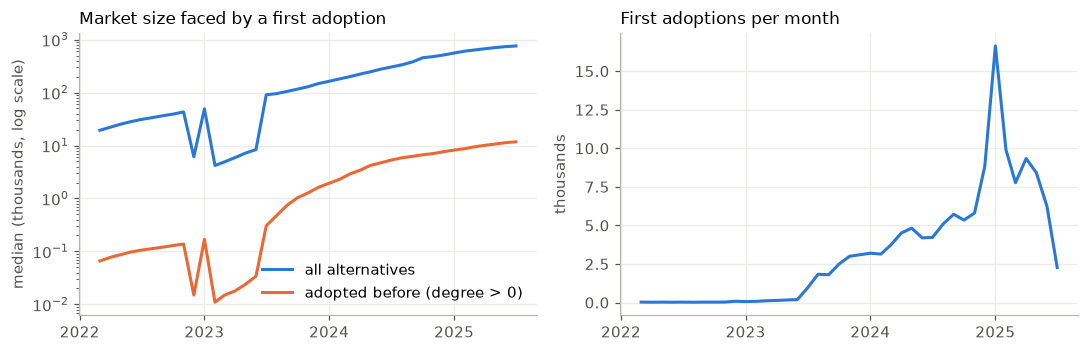

In [15]:
pa["month"] = ts(pa.t).dt.to_period("M").dt.to_timestamp()
g = pa.groupby("month").agg(market=("market", "median"), used=("market_used", "median"), n=("market", "size"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
ax = axes[0]
ax.plot(g.index, g.market / 1e3, color=C[0], label="all alternatives")
ax.plot(g.index, g.used / 1e3, color=C[1], label="adopted before (degree > 0)")
ax.set_yscale("log"); ax.set_ylabel("median (thousands, log scale)"); ax.set_title("Market size faced by a first adoption", loc="left", fontsize=11); ax.legend(loc="lower right"); yearly(ax)
ax = axes[1]
ax.plot(g.index, g.n / 1e3, color=C[0])
ax.set_ylabel("thousands"); ax.set_title("First adoptions per month", loc="left", fontsize=11); yearly(ax)
plt.tight_layout(); plt.show()

**写作要点：**
- 市场的规模本身就是一个动机。中位数 344,678 个备选，其中在选择之前被用过（degree > 0）的只占约 1.5%，绝大多数从来没有被用过。
- 模态之间差别很大：文本市场的中位数约 51 万，视觉、语音、多模态只有 2–3 万。2023 年上半年市场中位数的下凹，可能是因为那几个月的首次采纳以图像生成为主，而图像生成的市场小。
- 2025 年 7 月只有 12 天的数据（快照截至 7 月 12 日），所以最后一个月的数值偏低。
- 这一点自然引出 Section 4 的两件事。一是开发者不可能逐个比较，二是对候选集抽样时必须保证热门的现任模型在场，这就是 PPS 设计。

## 7. 集中度：动机性事实
全部按首次采纳计算。

**指标定义：**
- **Top-k 份额：** 采纳次数最多的 k 个父模型所占的份额。
- **有效父模型数：** exp(H)，其中 H = −Σ p·log p 是采纳份额的熵。如果市场由 m 个份额相等的父模型构成，它就等于 m。
- **Gini 系数：** 只在至少被采纳一次的父模型之间计算，Gini = Σ(2i−n−1)·x_i / (n·Σx)，其中 x 升序排列。

In [16]:
cnt = pa.parent.value_counts()
p = cnt / cnt.sum()
summary = dict(首次采纳=f"{len(pa):,}", 被采纳过的父模型=f"{len(cnt):,}", Top1=pct(p.iloc[0]), Top10=pct(p.iloc[:10].sum()),
               Top100=pct(p.iloc[:100].sum()), 有效父模型数=f"{eff_n(cnt):,.0f}", Gini=f"{gini(cnt):.3f}",
               只被采纳一次的父模型占比=pct((cnt == 1).mean()))
show(pd.Series(summary).to_frame("值"))
rows = []
for mod, d in pa.groupby("modality_name"):
    cc = d.parent.value_counts(); pp = cc / cc.sum()
    rows.append(dict(模态=mod, 首次采纳=len(d), 父模型=len(cc), Top1=pp.iloc[0], Top10=pp.iloc[:10].sum(),
                     有效父模型数=eff_n(cc), Gini=gini(cc), 最大的父模型=nodes.model_id.iloc[cc.index[0]]))
show(pd.DataFrame(rows).set_index("模态").sort_values("首次采纳", ascending=False)
     .style.format({"首次采纳": "{:,}", "父模型": "{:,}", "Top1": "{:.1%}", "Top10": "{:.1%}", "有效父模型数": "{:,.0f}", "Gini": "{:.3f}"}))

,值
首次采纳,"133,390"
被采纳过的父模型,"15,450"
Top1,6.8%
Top10,21.9%
Top100,49.9%
有效父模型数,839
Gini,0.854
只被采纳一次的父模型占比,73.4%


,首次采纳,父模型,Top1,Top10,有效父模型数,Gini,最大的父模型
模态,,,,,,,
text,"99,615","11,791",6.5%,18.7%,813,0.849,distilbert/distilbert-base-uncased
image_gen,"16,590",837,54.4%,87.2%,9,0.937,black-forest-labs/FLUX.1-dev
speech,"5,866",829,25.7%,70.8%,40,0.840,openai/whisper-small
vision,"5,243",582,26.4%,66.7%,42,0.844,google/vit-base-patch16-224-in21k
multimodal,"4,308",522,7.0%,41.2%,106,0.784,Qwen/Qwen2-VL-7B-Instruct
unknown,"1,658",857,2.3%,14.7%,504,0.430,facebook/wav2vec2-base
other,110,32,60.0%,80.0%,7,0.667,lerobot/smolvla_base


In [17]:
red_orgs, is_red = redistributors(nodes, E)
top = cnt.head(25).rename("首次采纳").to_frame()
top["份额"] = top.首次采纳 / len(pa); top["累计份额"] = top.份额.cumsum()
top["模型"] = nodes.model_id.iloc[top.index].to_numpy()
top["模态"] = nodes.modality.iloc[top.index].to_numpy()
top["创建"] = ts(birth[top.index]).strftime("%Y-%m").to_numpy()
top["大机构"] = nodes.major_org.iloc[top.index].to_numpy()
top["再分发账号"] = is_red[top.index]
show(top.reset_index(drop=True)[["模型", "模态", "创建", "大机构", "再分发账号", "首次采纳", "份额", "累计份额"]]
     .style.format({"首次采纳": "{:,}", "份额": "{:.2%}", "累计份额": "{:.1%}"}))
print(f"再分发账号（{len(red_orgs)} 个），例如：", red_orgs[:15])

,模型,模态,创建,大机构,再分发账号,首次采纳,份额,累计份额
0,black-forest-labs/FLUX.1-dev,image_gen,2024-07,True,False,"9,026",6.77%,6.8%
1,distilbert/distilbert-base-uncased,text,2022-03,True,False,"6,497",4.87%,11.6%
2,stabilityai/stable-diffusion-xl-base-1.0,image_gen,2023-07,True,False,"2,684",2.01%,13.6%
3,google-bert/bert-base-uncased,text,2022-03,True,False,"1,937",1.45%,15.1%
4,google-bert/bert-base-cased,text,2022-03,True,False,"1,750",1.31%,16.4%
5,openai/whisper-small,speech,2022-09,True,False,"1,507",1.13%,17.5%
6,unsloth/llama-3-8b-bnb-4bit,text,2024-04,False,True,"1,505",1.13%,18.7%
7,Gensyn/Qwen2.5-0.5B-Instruct,text,2025-03,False,False,"1,471",1.10%,19.8%
8,google-t5/t5-small,text,2022-03,True,False,"1,401",1.05%,20.8%
9,google/vit-base-patch16-224-in21k,vision,2022-03,True,False,"1,383",1.04%,21.9%


再分发账号（366 个），例如： ['1-lock', '3mei', '4bit', '893790183LZW', 'AIDSC', 'AIFunOver', 'AIventurer', 'AXERA-TECH', 'Aashraf995', 'Alcoft', 'Aldaris', 'AlekseyElygin', 'Alex01837178373', 'Andrewwwwww', 'Andyrasika']


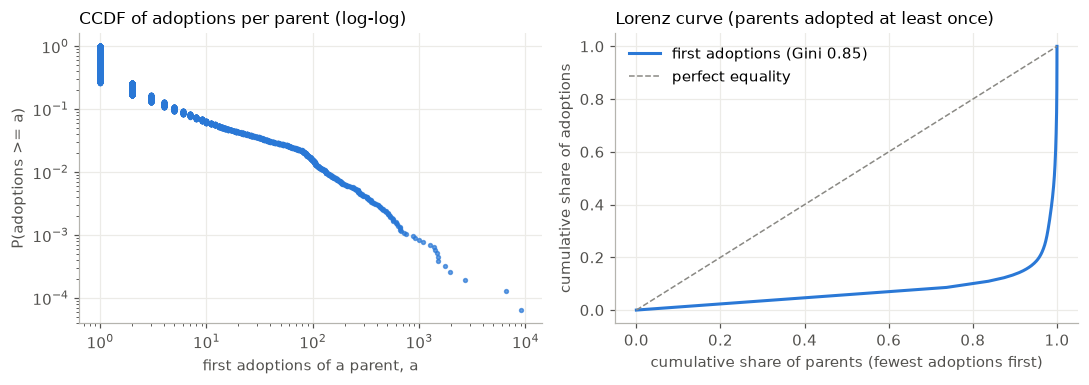

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
x = np.sort(cnt.to_numpy())[::-1]
ccdf = np.arange(1, len(x) + 1) / len(x)
ax.loglog(x, ccdf, color=C[0], marker="o", ms=2.5, lw=0, alpha=.7)
ax.set_xlabel("first adoptions of a parent, a"); ax.set_ylabel("P(adoptions >= a)")
ax.set_title("CCDF of adoptions per parent (log-log)", loc="left", fontsize=11)
ax = axes[1]
xs = np.sort(cnt.to_numpy()); L = np.r_[0, np.cumsum(xs) / xs.sum()]; F = np.linspace(0, 1, len(L))
ax.plot(F, L, color=C[0], label=f"first adoptions (Gini {gini(cnt):.2f})")
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls="--", label="perfect equality")
ax.set_xlabel("cumulative share of parents (fewest adoptions first)"); ax.set_ylabel("cumulative share of adoptions")
ax.set_title("Lorenz curve (parents adopted at least once)", loc="left", fontsize=11); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

,首次采纳,Top10,有效父模型数,领先者,领先者份额,Top10更替
季度,,,,,,
2022Q1,29,37.9%,28,FacebookAI/xlm-roberta-base,6.9%,nan%
2022Q2,72,45.8%,34,distilbert/distilbert-base-uncased,19.4%,90%
2022Q3,77,54.5%,30,distilbert/distilbert-base-uncased,19.5%,50%
2022Q4,144,47.9%,51,openai/whisper-small,11.8%,40%
2023Q1,253,60.1%,31,runwayml/stable-diffusion-v1-5,30.8%,50%
2023Q2,487,62.0%,29,runwayml/stable-diffusion-v1-5,34.9%,30%
2023Q3,"4,580",41.6%,138,distilbert/distilbert-base-uncased,11.7%,50%
2023Q4,"8,583",33.2%,206,distilbert/distilbert-base-uncased,10.7%,30%
2024Q1,"10,071",30.3%,316,distilbert/distilbert-base-uncased,8.9%,20%


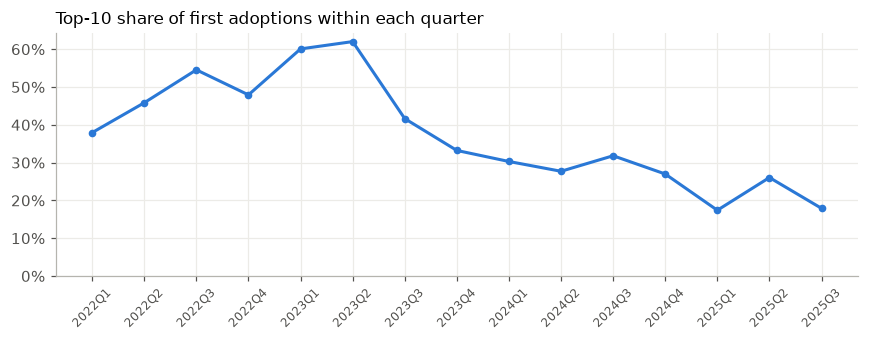

In [19]:
# concentration over time: quarterly, within-quarter shares
pa["q"] = ts(pa.t).dt.to_period("Q")
rows, prev = [], None
for qq, d in pa.groupby("q"):
    cc = d.parent.value_counts(); pp = cc / cc.sum(); top10 = set(cc.index[:10])
    rows.append(dict(季度=str(qq), 首次采纳=len(d), Top10=pp.iloc[:10].sum(), 有效父模型数=eff_n(cc),
                     领先者=nodes.model_id.iloc[cc.index[0]], 领先者份额=pp.iloc[0],
                     Top10更替=np.nan if prev is None else 1 - len(top10 & prev) / 10))
    prev = top10
Q = pd.DataFrame(rows).set_index("季度")
show(Q.style.format({"首次采纳": "{:,}", "Top10": "{:.1%}", "有效父模型数": "{:,.0f}", "领先者份额": "{:.1%}", "Top10更替": "{:.0%}"}))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(range(len(Q)), Q.Top10, color=C[0], marker="o", ms=4)
ax.set_xticks(range(len(Q))); ax.set_xticklabels(Q.index, rotation=45, fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.set_ylim(0, None)
ax.set_title("Top-10 share of first adoptions within each quarter", loc="left", fontsize=11); plt.tight_layout(); plt.show()

**写作要点：**
- **全样本 Top-10 份额（21.9%）低于多数季度内的 Top-10 份额**（2023Q3–2024Q4 各季度为 27–42%；2023Q2 及以前每季度只有 29–487 次首次采纳，份额高达 38–62%，但样本太小，不宜在正文引用）。这是因为领先者在更替：相邻季度之间 Top-10 有 20–60% 被换掉，领先者从 distilbert 换成 stable-diffusion-v1-5，再换成 FLUX.1-dev。每个季度都很集中，但集中在谁身上一直在变。这对 Section 6 很重要，因为生长模拟需要复现这种更替。
- **模态之间差异极大：** 图像生成的有效父模型数只有 9（FLUX.1-dev 一个就占 54%），文本是 813。正文可以用一句话点出，按模态的表放进附录。
- **Top-25 里既有大机构的基座，也有再分发账号**（如 unsloth 的 4-bit 版本）和非机构账号（如 Gensyn、llm-jp）。这个表适合放在附录，给读者一个具体的印象。
- 正文这一段的逻辑：极度集中 → 三种解释都能产生集中 → 需要一个能把它们分开的模型。不要在这一段暗示"集中就是因为流行"。

## 8. 被选中的父模型是什么样的
这些是被选中的父模型在选择当时的属性。它们帮助读者建立直觉，但不能代替 Section 5 的估计结果，因为没有和备选做比较。

In [20]:
age_d = (pa.t.to_numpy() - birth[pa.parent.to_numpy()]) / 86400
d = pa.parent_deg
desc = {
    "选择前 degree = 0 的比例（选了一个从没被用过的模型）": pct((d == 0).mean()),
    "选择前 degree 的中位数": f"{d.median():,.0f}",
    "选择前 degree 的 90 分位": f"{d.quantile(.9):,.0f}",
    "父模型年龄中位数（天）": f"{np.median(age_d):,.0f}",
    "父模型年龄 ≤ 30 天的比例": pct((age_d <= 30).mean()),
    "父模型由大机构发布": pct(nodes.major_org.to_numpy()[pa.parent].mean()),
    "父模型由再分发账号发布": pct(is_red[pa.parent].mean()),
    "父模型是作者自己的模型": pct((nodes.author_code.to_numpy()[pa.parent] == pa.author.to_numpy()).mean()),
    "父模型是回填（legacy）模型": pct(nodes.legacy.to_numpy()[pa.parent].mean()),
}
show(pd.Series(desc).to_frame("首次采纳"))
bins = [-1, 0, 9, 99, 999, 9999, 10**7]
lab = ["0", "1–9", "10–99", "100–999", "1,000–9,999", "≥10,000"]
show(pd.cut(d, bins, labels=lab).value_counts(normalize=True).reindex(lab).rename("首次采纳占比").to_frame().style.format("{:.1%}"))

,首次采纳
选择前 degree = 0 的比例（选了一个从没被用过的模型）,11.4%
选择前 degree 的中位数,167
选择前 degree 的 90 分位,"4,256"
父模型年龄中位数（天）,243
父模型年龄 ≤ 30 天的比例,14.3%
父模型由大机构发布,59.1%
父模型由再分发账号发布,13.0%
父模型是作者自己的模型,5.1%
父模型是回填（legacy）模型,22.4%


,首次采纳占比
parent_deg,
0,11.4%
1–9,9.3%
10–99,20.9%
100–999,35.2%
"1,000–9,999",18.8%
"≥10,000",4.3%


## 9. 开发者能看到的信号：四组特征
每一对（首次采纳 k，候选 j）一行。所有特征只用子模型出生之前的模型和边计算，作者"历史"不含候选本身。下面先给出定义，再看描述统计：
- **被选中的父模型**的平均值；
- **整个市场**的平均值：对抽样候选按 1/π 加权（Horvitz–Thompson），用来估计"如果在全市场逐个看，平均是多少"。

两列的差别就是一个直观的"被选中者与众不同之处"。它是单变量比较，不控制其他特征。

In [21]:
FEAT_DESC = {
    "log_deg": ("流行", "log max(d,1)，d = 此前 finetune/adapter 子模型数"),
    "has_deg": ("流行", "1[d>0]：是否被用过"),
    "lrec30": ("流行", "log(1+近 30 天的子模型数)"),
    "log_age": ("流行", "log(1+年龄，天)"),
    "major_org": ("流行", "由大型 AI 机构发布"),
    "legacy": ("流行", "回填模型（2022-03-02 之前）"),
    "lquant": ("流行", "log(1+量化版本数)"),
    "lib_transformers": ("流行", "框架 = transformers"), "lib_peft": ("流行", "框架 = peft"),
    "lib_diffusers": ("流行", "框架 = diffusers"), "lib_sentence-transformers": ("流行", "框架 = sentence-transformers"),
    "redistributor": ("流行", "由再分发账号发布（≥20 个副本且副本占其模型 ≥50%）"),
    "ds_couse": ("流行", "log(1+在子模型的数据集上训练、由其他作者发布、选了该候选的更早模型数)"),
    "lco2": ("流行", "log(1+与作者共用过小众父模型、并用过该候选的其他作者数)"),
    "size_na": ("流行", "候选（或作者历史）的参数量缺失"),
    "txt_na": ("流行", "候选没有可用的卡片文本"),
    "bench_na": ("流行", "候选没有 benchmark 分数"),
    "bench_z": ("通用质量", "model-index benchmark 分数，按 benchmark 标准化（缺失为 0）"),
    "task_hist": ("需求匹配", "候选的任务出现在作者历史中"),
    "lang_hist": ("需求匹配", "候选与作者历史共享一种语言"),
    "size_dist": ("需求匹配", "|log 参数量(j) − 作者历史的 log 参数量中位数|"),
    "ds_lang": ("需求匹配", "候选的语言在子模型数据集的其他模型中常见（≥30%）"),
    "ds_task": ("需求匹配", "候选的任务在子模型数据集的其他模型中常见（≥30%）"),
    "txt_sim": ("需求匹配", "子模型与候选卡片的 TF-IDF 余弦（清洗后；双方 ≥5 词才计算）"),
    "author_reuse": ("惯性", "候选是作者用过的父模型（方案 A 中恒为 0，这些行已删去）"),
    "author_family": ("惯性", "候选属于作者用过的家族"),
    "same_author": ("惯性", "候选由作者本人发布"),
    "is_last": ("惯性", "候选是作者上一次用的父模型（方案 A 中几乎恒为 0）"),
}
GN = {"pop": "流行", "qual": "通用质量", "match": "需求匹配", "inertia": "惯性"}
assert set(FEAT_DESC) == set(ALL), set(ALL) ^ set(FEAT_DESC)
print({GN[g]: len(v) for g, v in GROUPS.items()}, "共", len(ALL), "个；author_reuse 和 is_last 在方案 A 中恒为 0，进入估计的是 26 个")

{'流行': 17, '通用质量': 1, '需求匹配': 6, '惯性': 4} 共 28 个；author_reuse 和 is_last 在方案 A 中恒为 0，进入估计的是 26 个


In [22]:
from hfpa.v2data import load_rows
rows, _ = load_rows("v2_pps", "planA")
print(f"方案 A 的候选行 {len(rows):,}，选择 {rows.choice_id.nunique():,}")
ch_ = rows[rows.chosen == 1]
w = np.exp(-rows.log_q.to_numpy(np.float64))                 # 1 / pi
nc = rows.chosen.to_numpy() == 0
out = []
for f in ALL:
    x = rows[f].to_numpy(np.float64)
    out.append(dict(组=FEAT_DESC[f][0], 特征=f, 定义=FEAT_DESC[f][1],
                    被选中的均值=ch_[f].mean(), 市场均值_HT加权=np.average(x[nc], weights=w[nc]),
                    候选集均值_未加权=x[nc].mean(), 非零比例_被选中=(ch_[f] != 0).mean()))
F = pd.DataFrame(out).set_index("特征")
show(F.style.format({"被选中的均值": "{:.3f}", "市场均值_HT加权": "{:.4f}", "候选集均值_未加权": "{:.3f}", "非零比例_被选中": "{:.1%}"}))

方案 A 的候选行 39,893,975，选择 133,216


,组,定义,被选中的均值,市场均值_HT加权,候选集均值_未加权,非零比例_被选中
特征,,,,,,
log_deg,流行,"log max(d,1)，d = 此前 finetune/adapter 子模型数",4.786,0.0124,0.764,86.3%
lrec30,流行,log(1+近 30 天的子模型数),3.504,0.0034,0.381,83.9%
major_org,流行,由大型 AI 机构发布,0.591,0.0056,0.089,59.1%
has_deg,流行,1[d>0]：是否被用过,0.886,0.0145,0.156,88.6%
legacy,流行,回填模型（2022-03-02 之前）,0.224,0.0394,0.081,22.4%
log_age,流行,log(1+年龄，天),5.139,5.2696,5.325,100.0%
size_na,流行,候选（或作者历史）的参数量缺失,0.738,0.8122,0.867,73.8%
txt_na,流行,候选没有可用的卡片文本,0.828,0.9321,0.909,82.8%
bench_na,流行,候选没有 benchmark 分数,0.988,0.9956,0.995,98.8%


In [23]:
# candidate sets
g = rows.groupby("choice_id")
cs = pd.DataFrame({"size": g.size(), "certain": (rows.log_q == 0).groupby(rows.choice_id).sum()})
print(f"候选集大小：均值 {cs['size'].mean():.1f}，中位数 {cs['size'].median():.0f}；"
      f"π = 1 的候选平均 {cs.certain.mean():.1f} 个/次")
print(f"被选父模型的 π = 1（属于必然入选的热门层）的比例：{pct((ch_.log_q == 0).mean())}")
# demand signals: does the choice carry any information about the developer's need?
sig = ch_.set_index("choice_id")[SIGNAL].astype(bool)
cover = pd.Series({"作者历史（hist_has）": sig.hist_has.mean(), "数据集档案（ds_has）": sig.ds_has.mean(),
                   "卡片文本 ≥5 词（txt_has）": sig.txt_has.mean(), "至少一种": sig.any(axis=1).mean(),
                   "三种都没有": (~sig.any(axis=1)).mean()})
print("首次采纳中，有需求信号的比例：")
show(cover.rename("占比").to_frame().style.format("{:.1%}"))

候选集大小：均值 299.5，中位数 299；π = 1 的候选平均 8.5 个/次
被选父模型的 π = 1（属于必然入选的热门层）的比例：27.1%
首次采纳中，有需求信号的比例：


,占比
作者历史（hist_has）,47.7%
数据集档案（ds_has）,12.4%
卡片文本 ≥5 词（txt_has）,25.2%
至少一种,67.2%
三种都没有,32.8%


**写作要点：**
- **分组的原则：** 一个信号如果对所有开发者都一样、和需求无关，就归入流行。所以文档是否完整也算流行（是可见度，不是需求）。需求匹配必须因开发者而异。
- **需求信号的覆盖率：** 上表"三种都没有"的选择，需求匹配无法起作用。这一点在正文中要坦白说明，Section 5 已经报告了只看有信号选择的结果。
- **HT 加权的市场均值：** 这一列适合作为描述，说明被选中的模型和"典型的备选"有多不同。has_deg：被选中的 88.6% 被用过，市场里只有约 1.5%。major_org：被选中的 59.1%，市场里约 0.6%。task_hist：被选中的 38.8%，市场里 18.3%。流行特征的差距比匹配特征大得多，这和 Section 5 的结论方向一致，但这里只是单变量比较。
- **需求信号覆盖率：** 67.2% 的首次采纳至少有一种需求信号（作者历史 47.7%，卡片文本 25.2%，数据集档案 12.4%），32.8% 一种都没有。
- **候选集：** 平均约 300 个候选，其中约 8.5 个 π = 1。被选父模型有 27.1% 落在 π = 1 的层里，其余的靠抽样进入候选集。

## 10. 防照抄：继承检验与卡片文本清洗
**问题：** 子模型的卡片大量照抄父模型。如果直接比较"子模型与候选是否相似"，真实父模型会机械地胜出。

**检验方法：** 对每个元数据字段，比较子模型与真实父模型的一致率（identical），以及子模型与随机父模型的一致率（chance）。随机父模型取同月、同模态的另一个选择的父模型，绝不取本选择自己的父模型。

指标是 Cohen's κ = (identical − chance) / (1 − chance)，表示超出偶然的一致程度。只统计双方都声明了该字段的选择（both_has 是这种选择的比例）。

In [24]:
inh = pd.read_csv(T / "v2_inherit.csv")
inh["kappa_check"] = (inh.identical - inh.chance) / (1 - inh.chance)
FIELD = {"params_b": "参数量", "licenses": "许可证", "languages": "语言", "pipeline_tag": "任务", "datasets": "数据集", "library_name": "框架"}
USE = {"params_b": "照抄为主 → 不作需求（size_dist 只用作者历史）", "licenses": "照抄为主 → 不作需求",
       "languages": "中度继承 → 只用作者历史和数据集档案", "pipeline_tag": "中度继承 → 只用作者历史和数据集档案",
       "datasets": "基本是子模型自己的 → 用作需求来源（并去掉与父模型共享的数据集）", "library_name": "几乎不继承，但是工具格式 → 归入流行"}
x = inh[inh["sample"] == "first author-parent choices"].copy()
x["字段"] = x.field.map(FIELD); x["处理"] = x.field.map(USE)
show(x.sort_values("cohen_kappa", ascending=False).set_index("字段")[["both_has", "identical", "chance", "cohen_kappa", "kappa_check", "处理"]]
     .style.format({"both_has": "{:.2f}", "identical": "{:.2f}", "chance": "{:.2f}", "cohen_kappa": "{:.2f}", "kappa_check": "{:.2f}"}))
print("全部选择（不只是首次采纳）的结果：")
show(inh[inh["sample"] == "all choices"].set_index("field")[["both_has", "identical", "chance", "cohen_kappa"]].round(3))

,both_has,identical,chance,cohen_kappa,kappa_check,处理
字段,,,,,,
参数量,0.25,0.86,0.11,0.84,0.84,照抄为主 → 不作需求（size_dist 只用作者历史）
许可证,0.73,0.83,0.35,0.74,0.74,照抄为主 → 不作需求
语言,0.23,0.75,0.55,0.44,0.44,中度继承 → 只用作者历史和数据集档案
任务,0.57,0.69,0.52,0.34,0.34,中度继承 → 只用作者历史和数据集档案
数据集,0.08,0.13,0.01,0.12,0.12,基本是子模型自己的 → 用作需求来源（并去掉与父模型共享的数据集）
框架,0.90,0.68,0.65,0.07,0.07,几乎不继承，但是工具格式 → 归入流行


全部选择（不只是首次采纳）的结果：


,both_has,identical,chance,cohen_kappa
field,,,,
pipeline_tag,0.430,0.709,0.570,0.324
library_name,0.939,0.495,0.479,0.031
languages,0.162,0.800,0.607,0.490
datasets,0.048,0.093,0.008,0.086
licenses,0.547,0.848,0.352,0.765
params_b,0.421,0.930,0.059,0.926


**卡片文本的清洗**（`results/tables/v2/text_build.md`）：
- **模板段落：** 出现在 ≥20 张卡片里的段落，包括用 MinHash 找到的近似重复段落（5 词片段，Jaccard ≥ 0.8）。
- **照抄段落：** 在不晚于子模型的卡片中已经出现过的段落。
- **名称：** 删除机构名、家族名（仓库名的第一个词）和含数字的词，避免共享的模型名制造相似度。

In [25]:
print((T / "text_build.md").read_text())
print("txt_sim 的最低词数门槛（敏感性）：")
show(pd.read_csv(T / "v2_text_threshold.csv"))

# v2 card text build

cards 1,062,460; unique paragraph keys 706,479; frequent 12,871; banned incl. near-duplicate clusters 23,093; child paragraphs dropped as template 7,588,059, as copied from an earlier card 120,986, kept 4,695,034.
name tokens removed 715; vocabulary 116,121.

child documents by token count (after removal):

|   min_tokens |   share_of_child_cards |
|-------------:|-----------------------:|
|            1 |              0.855967  |
|            5 |              0.18255   |
|           10 |              0.0863177 |
|           20 |              0.046785  |
|           50 |              0.0271253 |

txt_sim 的最低词数门槛（敏感性）：


,min_tokens,txt_sim_coef,txt_sim_se,share_choices_with_text,match_share,pop_share
0,5,1.687380,0.073493,0.231710,0.051993,0.916390
1,10,6.452812,0.096512,0.139155,0.053170,0.914452
2,20,10.038647,0.209083,0.085466,0.053214,0.914365
3,50,16.496330,0.429468,0.050881,0.052066,0.914865


**写作要点：**
- 这一段是审稿人最容易质疑"机械相关"的地方，所以要写清楚三层防护：
  1. 哪些字段不用；
  2. 数据集档案只用选择之前的模型，并去掉与被选父模型共享的数据集，还去掉候选自己的子模型；
  3. 卡片文本去模板、去照抄、去名称。
- Section 5 的安慰剂检验（换成别人的需求）是这一段的事后验证，可以在这里预告一句。

## 11. 训练集与留出集
按时间留出最后 10% 的选择（以全部选择排序后确定切点 t_h）。固定效应集合 = t_h 时刻 degree 最高的 500 个模型，是事前确定的，不依赖未来的采纳。

In [26]:
fit = pd.read_csv(T / "v2_pps_clogit_fit.csv").set_index("model").loc["full"]
t_h = ch.t[ch.holdout].min()
in_rows = set(rows.choice_id.unique())
steps = pd.DataFrame([
    ("首次采纳（pair_first）", len(pa)),
    ("且候选集中有被选父模型（删去作者用过的父模型后）", int(pa.choice_id.isin(in_rows).sum())),
    ("  其中训练集（t < t_h）", int((pa.choice_id.isin(in_rows) & ~pa.holdout).sum())),
    ("  其中留出集（t ≥ t_h）", int((pa.choice_id.isin(in_rows) & pa.holdout).sum())),
    ("估计用的训练选择（clogit 拟合的 n）", int(fit.n)),
], columns=["样本", "数量"])
show(steps.style.format({"数量": "{:,}"}))
print(f"留出切点 t_h = {ts(t_h)}；留出集占全部选择 {pct(ch.holdout.mean())}；占首次采纳 {pct(pa.holdout.mean())}")
fe = rows.loc[rows.chosen == 1, ["choice_id", "fe"]].set_index("choice_id").fe
fe_hit = (fe > 0)                                            # fe = 0: not a hub; 1..500: hub id
ho = ch.set_index("choice_id").holdout
print(f"被选父模型属于 500 个固定效应枢纽的比例：训练集 {pct(fe_hit[~ho.reindex(fe.index).to_numpy()].mean())}，"
      f"留出集 {pct(fe_hit[ho.reindex(fe.index).to_numpy()].mean())}")

,样本,数量
0,首次采纳（pair_first）,"133,390"
1,且候选集中有被选父模型（删去作者用过的父模型后）,"133,216"
2,其中训练集（t < t_h）,"117,509"
3,其中留出集（t ≥ t_h）,"15,707"
4,估计用的训练选择（clogit 拟合的 n）,"117,509"


留出切点 t_h = 2025-05-05 09:48:33；留出集占全部选择 9.8%；占首次采纳 11.8%
被选父模型属于 500 个固定效应枢纽的比例：训练集 76.7%，留出集 60.8%


**写作要点：** 这几个口径要在正文或脚注里交代清楚：
- 首次采纳共 133,390 次；
- 其中 133,216 次的被选父模型留在方案 A 的候选集中。`load_rows` 会删掉带 `author_reuse = 1` 的候选行，以及没有被选行的选择。差 174 次（0.13%），具体是哪种情况造成的还没有逐一核实。
- 训练集 117,509 次，留出集 15,707 次。
- 留出集占全部选择的 9.8%，但占首次采纳的 11.8%，因为后期的首次采纳比例更高。
- **固定效应枢纽覆盖率：** 被选父模型属于 500 个固定效应枢纽的比例，训练集 76.7%，留出集 60.8%。留出期有更多选择落在切点时还不是枢纽的模型上，这可能是固定效应在样本外帮助有限的原因之一（Section 5）。

## 12. 数字核对：论文宏与本笔记重算值
`tables/numbers.tex` 由 `scripts/paper_tables.py` 生成。下面把 Section 3 用到的宏和本笔记重算的值放在一起比较。

In [27]:
macros = dict(re.findall(r"\\newcommand\{\\(\w+)\}\{([^}]*)\}", (REPO / "ec_adoption" / "tables" / "numbers.tex").read_text()))
sec3 = (REPO / "ec_adoption" / "sections" / "3_data.tex").read_text()
used = sorted((set(re.findall(r"\\([a-zA-Z]+)\{\}", sec3)) | set(re.findall(r"\\([a-z]+[A-Z]\w*)", sec3))) & set(macros))
mine = {"nModels": f"{len(nodes):,}", "nAuthorsAll": f"{nodes.author_code.nunique():,}", "nEdges": f"{len(E):,}",
        "nAdapter": f"{(E.rel_type == 'adapter').sum():,}", "nFinetune": f"{(E.rel_type == 'finetune').sum():,}",
        "nChoices": f"{len(ch):,}", "nDecisions": f"{int(ch.dfirst24.sum()):,}", "nFirst": f"{len(pa):,}",
        "nFirstAuthors": f"{pa.author.nunique():,}", "nFirstParents": f"{len(cnt):,}", "nTrain": f"{int(fit.n):,}",
        "topOneReal": f"{100 * p.iloc[0]:.1f}", "topTenReal": f"{100 * p.iloc[:10].sum():.1f}", "effReal": f"{eff_n(cnt):,.0f}",
        "marketMedian": f"{pa.market.median():,.0f}", "shareText": f"{100 * (pa.modality_name == 'text').mean():.0f}",
        "tStart": f"{ts(ch.t.min()):%B %Y}", "tEnd": f"{ts(ch.t.max()):%B %Y}", "tHold": ts(t_h).strftime("%B %-d, %Y")}
chk = pd.DataFrame([(m, macros.get(m), mine.get(m)) for m in used], columns=["宏", "论文中的值", "本笔记重算"])
chk["一致"] = np.where(chk.本笔记重算.isna(), "（非本节计算）", np.where(chk.论文中的值 == chk.本笔记重算, "✓", "✗"))
show(chk.set_index("宏"))

,论文中的值,本笔记重算,一致
宏,,,
effReal,839,839,✓
marketMedian,"344,678","344,678",✓
nAdapter,"243,643","243,643",✓
nAuthorsAll,"391,746","391,746",✓
nChoices,"422,714","422,714",✓
nDecisions,"199,464","199,464",✓
nEdges,"574,531","574,531",✓
nFinetune,"188,819","188,819",✓
nFirst,"133,390","133,390",✓


## 13. 写作时要处理的问题与待办

**必须补的：**
- [ ] 数据来源引用：`modelbiome/ai_ecosystem_withmodelcards`，写明快照日期 2025-07-12（Section 3 的 todo）。
- [ ] 说明 `likes` 和 `downloads` 是快照值，没有进模型；流行信号全部按选择时刻重算（§1）。
- [ ] 样本构造表：原始模型 → 边 → 选择 → 决策 → 首次采纳 → 训练集（§4、§5、§11）。

**审稿人可能追问的问题，以及可用的回答：**

| 问题 | 可用的回答（本笔记中的位置） |
|---|---|
| 声明的 base model 可靠吗？ | 声明是 Hub 生成的结构化标签，不是自由文本；悬空父模型只占 1.4%；占位节点保留了被删除的大父模型（§3）。没声明的子模型看不到，这一点要列为局限 |
| 批量账号会不会主导结果？ | 首次采纳把每个作者–父模型对只算一次；用前 1% 作者占比的前后对比说明（§5） |
| 开发者真的面对几十万个备选吗？ | 不是逐个比较。市场是"可能的备选"，Section 4 的抽样让热门现任者总在候选集里；被用过的备选只占一小部分（§6） |
| 集中度是不是少数作者造成的？ | 作者层面的分布（§5）和父模型层面的集中度（§7）分开报告 |
| 时间是否可靠？ | 回填之前的模型只作初始网络；子模型早于父模型的边已删去（§3） |
| 元数据照抄会不会制造匹配？ | 继承检验和三层防护（§10），再加上 Section 5 的安慰剂检验 |
| 模态划分是否合理？ | 跨模态的选择只有 10,344 次，已删去（§4）；按模态的集中度见 §7 |

**可选的图（主文最多一张）：**
1. 集中度 CCDF 或 Lorenz 曲线（§7）：最直接支撑"极度集中"；
2. 季度 Top-10 份额和领先者更替（§7）：同时铺垫 Section 6；
3. 市场规模随时间增长（§6）：铺垫 Section 4 的抽样设计。